# Selección del número de épocas de la CRNN con la partición 80/20

Se entrena la CRNN desde cero hasta un máximo de 100 épocas con las mismas 80 personas del notebook mixto. Después de cada época se calcula el F1 macro en las mismas 20 personas reservadas. La arquitectura, las ventanas, Adam, el tamaño de lote y la semilla se mantienen fijos.

Se elige la época con mayor F1 macro. En caso de empate se conserva la primera. La época 15 sirve como referencia. Como las 20 personas intervienen en la elección, el máximo obtenido describe la selección en este grupo.

**Corrida guardada.** Se detuvo por solicitud después de la época 66. La sección de resultados carga la curva y el punto de control conservados en disco; puede revisarse tras reiniciar el kernel sin volver a entrenar.

In [1]:
import hashlib
import json
import os
import sys
from datetime import datetime
from pathlib import Path
from time import perf_counter
from uuid import uuid4

os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '5')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.special import softmax
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data.dvc').is_file())
sys.path.insert(0, str(ROOT/'Notebooks/auxiliares_dart_crnn'))
from crnn_contextual_mixto import bloques, entrenar_crnn, prob_crnn

DATA = ROOT/'data'
AUX = ROOT/'Notebooks/auxiliares_dart_crnn'
ficha = json.loads((DATA/'experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036/referencia_seleccion_80_20.json').read_text('utf8'))
contrato = ficha['contrato']
CLASES = np.array(contrato['clases'])
DESFASES = tuple(contrato['desfases'])
SEMILLA = 42
SEMILLA_PARTICION = 42
EPOCAS = 100
tf.config.experimental.enable_op_determinism()

## Personas y entradas preprocesadas

Las etiquetas e índices se leen de las tablas supervisadas. Cada espectro conserva todas las épocas de su propia noche. El entrenamiento y las métricas utilizan las épocas con etiqueta válida.

In [2]:
personas_desarrollo = set(contrato['personas_entrenamiento'])
registros_desarrollo = contrato['registros_entrenamiento']
assert len(personas_desarrollo) == 80 and len(registros_desarrollo) == 158
partes = []
for manifiesto in sorted((DATA/'processed/supervised').glob('*/manifest.json')):
    cache = json.loads(manifiesto.read_text('utf8'))
    cohorte = 'Cassette' if cache['record_ids'][0].startswith('SC') else 'Telemetry'
    if cache['preprocessing'] != contrato['preprocesamiento_dart'][cohorte]:
        continue
    meta = pd.read_parquet(manifiesto.parent/'metadata.parquet', columns=['record_id','subject_id','epoch_index'])
    meta['etapa'] = pd.read_parquet(manifiesto.parent/'labels.parquet')['stage'].to_numpy()
    partes.append(meta.assign(cohorte=cohorte))

desarrollo = pd.concat(partes, ignore_index=True)
assert desarrollo.subject_id.nunique() == 100 and desarrollo.record_id.nunique() == 197
assert not desarrollo.duplicated(['record_id','epoch_index']).any()
personas = desarrollo[['cohorte','subject_id']].drop_duplicates().sort_values(['cohorte','subject_id'])
it, iv = next(StratifiedKFold(5, shuffle=True, random_state=SEMILLA_PARTICION).split(personas, personas.cohorte))
ids_train = set(personas.iloc[it].subject_id)
ids_val = set(personas.iloc[iv].subject_id)
assert len(ids_train) == 80 and len(ids_val) == 20 and ids_train.isdisjoint(ids_val)
entreno = desarrollo[desarrollo.subject_id.isin(ids_train)]
validacion = desarrollo[desarrollo.subject_id.isin(ids_val)].sort_values(['record_id','epoch_index']).reset_index(drop=True)

assert ids_train == personas_desarrollo
assert set(entreno.record_id) == set(registros_desarrollo)
assert len(entreno) == contrato['segmentos_entrenamiento'] == 365283 and len(validacion) == 92369
assert entreno.record_id.nunique() == 158 and validacion.record_id.nunique() == 39

# Seleccionar la receta y las señales de la corrida 80/20.
receta_espectral = '61a5f1dc5fa2f1b4'
carpeta_espectral = DATA/'processed/crnn_espectral'/receta_espectral
receta = json.loads((carpeta_espectral/'preprocesamiento.json').read_text('utf8'))
assert receta['canales'] == contrato['canales_crnn'] and receta['bandas'] == contrato['bandas_hz']
entradas = {}
for rid, grupo in desarrollo.groupby('record_id', sort=False):
    cohorte = grupo.cohorte.iat[0].lower()
    archivo, = (DATA/('sleep-'+cohorte)).glob(f'{rid}*-PSG.edf')
    digest = hashlib.sha256()
    with archivo.open('rb') as f:
        for bloque in iter(lambda: f.read(4*1024*1024), b''):
            digest.update(bloque)
    huella = digest.hexdigest()
    if rid in registros_desarrollo:
        assert huella == registros_desarrollo[rid]['psg']
    ruta = carpeta_espectral/f'{archivo.stem}-{huella}.npy'
    entradas[rid] = np.load(ruta, mmap_mode='r', allow_pickle=False)
assert all(x.dtype == np.float32 and x.shape[1:] == (6,96) for x in entradas.values())
resumen = pd.concat({'Entrenamiento': entreno, 'Prueba usada para elegir la época': validacion}, names=['uso'])
display(resumen.groupby(['uso','cohorte']).agg(personas=('subject_id','nunique'), noches=('record_id','nunique'), segmentos=('etapa','size')))

personas  noches  segmentos
uso                               cohorte                               
Entrenamiento                     Cassette         62     122     330469
                                  Telemetry        18      36      34814
Prueba usada para elegir la época Cassette         16      31      84492
                                  Telemetry         4       8       7877

## Validación después de cada época

Se reúnen las ventanas por desfase para predecir por lotes. Cada ventana pertenece a una sola noche. Se combinan las tres predicciones de cada segmento mediante la misma media geométrica del modelo principal.

In [3]:
vistas = []
for desfase in DESFASES:
    secuencias, posiciones = [], []
    inicio = 0
    for rid, grupo in validacion.groupby('record_id', sort=False):
        noche = bloques(entradas[rid], desfase)
        secuencias.append(noche)
        posiciones.append(inicio + desfase + grupo.epoch_index.to_numpy())
        inicio += len(noche) * noche.shape[1]
    vistas.append((np.concatenate(secuencias), np.concatenate(posiciones)))
del secuencias, posiciones
y_val = pd.Categorical(validacion.etapa, categories=CLASES).codes

def probabilidades_validacion(red):
    log_p = np.zeros((len(validacion), len(CLASES)), dtype='float64')
    for secuencias, posiciones in vistas:
        p = red.predict(secuencias, batch_size=128, verbose=0).reshape(-1, len(CLASES))
        log_p += np.log(np.maximum(p[posiciones].astype('float64'), 1e-10))
    return softmax(log_p / len(vistas), axis=1)

## Entrenamiento y selección

Una sola trayectoria de entrenamiento permite comparar las épocas con los mismos pesos iniciales y el mismo orden de lotes hasta cada punto. Se guardan la curva completa y el modelo que alcanza el mejor F1 macro en validación. El tiempo de ajuste excluye la evaluación y la escritura de resultados.

In [ ]:
salida = AUX/'resultados_crnn'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
salida.mkdir(parents=True, exist_ok=False)
ruta_mejor = salida/'mejor_crnn.keras'
historial = []
mejor_f1 = -np.inf
mejor_epoca = 0
segundos_validacion = 0.
inicio_ajuste = perf_counter()

def evaluar_epoca(epoca, red):
    global mejor_f1, mejor_epoca, segundos_validacion
    inicio_val = perf_counter()
    p = probabilidades_validacion(red)
    if epoca == 1:
        rid = validacion.record_id.iat[0]
        g = validacion[validacion.record_id == rid]
        referencia = prob_crnn(red, entradas[rid], clases=CLASES, desfases=DESFASES)[g.epoch_index]
        np.testing.assert_allclose(p[g.index], referencia, rtol=1e-5, atol=1e-7)
    pred = p.argmax(axis=1)
    f1 = f1_score(y_val, pred, labels=np.arange(len(CLASES)), average='macro', zero_division=0)
    fila = dict(epoca=epoca, f1_macro=f1, exactitud=accuracy_score(y_val, pred),
                kappa=cohen_kappa_score(y_val, pred), perdida_log=log_loss(y_val, p, labels=np.arange(len(CLASES))),
                ajuste_acumulado_s=inicio_val-inicio_ajuste-segundos_validacion)
    historial.append(fila)
    if f1 > mejor_f1:
        temporal = salida/(uuid4().hex + '.keras')
        red.save(temporal)
        temporal.replace(ruta_mejor)
        mejor_f1, mejor_epoca = f1, epoca
    tmp = salida/'curva.tmp'
    pd.DataFrame(historial).to_csv(tmp, index=False)
    tmp.replace(salida/'curva.csv')
    segundos_validacion += perf_counter()-inicio_val
    print(f'Época {epoca:3d}/{EPOCAS} ({epoca/EPOCAS:.0%}) | F1 macro {f1:.4f} | mejor {mejor_f1:.4f} en época {mejor_epoca}', flush=True)

print(f'Inicio de CRNN desde cero. 80 personas en entrenamiento, 20 en evaluación. Resultados en {salida.relative_to(ROOT)}', flush=True)
red = entrenar_crnn(entreno, entradas, clases=CLASES, desfases=DESFASES, semilla=SEMILLA,
                    epocas=EPOCAS, al_terminar_epoca=evaluar_epoca)

## Resultados y verificación del punto de control

La tabla y la curva incluyen todas las épocas que completaron la evaluación. Se recarga el mejor modelo y se comprueba su F1 en las 20 personas reservadas. Para revisar un resultado existente basta con ejecutar las celdas de configuración, datos y ventanas de evaluación antes de esta celda.

,f1_macro,exactitud,kappa,perdida_log,ajuste_acumulado_s
epoca,,,,,
12,0.7912,0.9092,0.8389,0.2372,130.3077
15,0.7826,0.9063,0.8334,0.2399,165.4682
20,0.7903,0.9063,0.8342,0.2470,222.0345
25,0.7911,0.9097,0.8389,0.2468,273.4581
27,0.7934,0.9127,0.8444,0.2350,293.6135
30,0.7910,0.9108,0.8411,0.2478,324.8918
50,0.7793,0.9065,0.8334,0.2683,527.6295
66,0.7840,0.9058,0.8324,0.2848,691.7418


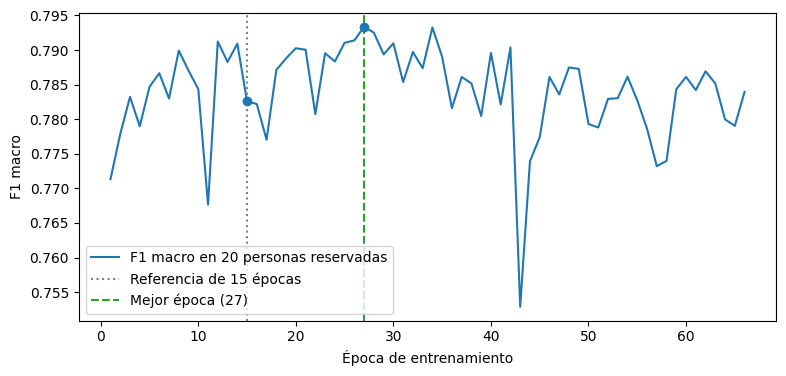

Épocas completadas: 66. Mejor época: 27. F1 macro 0.7934.
Diferencia frente a 15 épocas: +1.08 puntos porcentuales.
Notebooks\auxiliares_dart_crnn\resultados_crnn\20261119_182857_229701


In [4]:
if 'salida' not in globals():
    curvas = sorted((AUX/'resultados_crnn').glob('*/curva.csv'))
    if not curvas:
        raise FileNotFoundError('No hay una curva guardada del experimento.')
    salida = curvas[-1].parent

curva = pd.read_csv(salida/'curva.csv').set_index('epoca')
completadas = int(curva.index.max())
assert curva.index.tolist() == list(range(1, completadas + 1))
mejor_epoca = int(curva.f1_macro.idxmax())
mejor_f1 = float(curva.at[mejor_epoca,'f1_macro'])
seleccion = sorted({i for i in [12, 15, 20, 25, 30, 50, 75, EPOCAS, mejor_epoca, completadas] if i in curva.index})
display(curva.loc[seleccion].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curva.index, curva.f1_macro, label='F1 macro en 20 personas reservadas')
ax.scatter([15, mejor_epoca], curva.loc[[15, mejor_epoca],'f1_macro'], zorder=3)
ax.axvline(15, color='grey', linestyle=':', label='Referencia de 15 épocas')
ax.axvline(mejor_epoca, color='tab:green', linestyle='--', label=f'Mejor época ({mejor_epoca})')
ax.set(xlabel='Época de entrenamiento', ylabel='F1 macro')
ax.legend()
plt.show()

ruta_mejor = salida/'mejor_crnn.keras'
ganadora = tf.keras.models.load_model(ruta_mejor, compile=False)
probs_mejor = probabilidades_validacion(ganadora)
f1_recargado = f1_score(y_val, probs_mejor.argmax(1), labels=np.arange(len(CLASES)), average='macro')
np.testing.assert_allclose(f1_recargado, mejor_f1, rtol=0, atol=1e-10)
informe = dict(maximo_epocas=EPOCAS, epocas_completadas=completadas, mejor_epoca=mejor_epoca,
               estado='completo' if completadas == EPOCAS else 'interrumpido',
               semilla_modelo=SEMILLA, semilla_particion=SEMILLA_PARTICION, mejor_f1_macro=mejor_f1,
               f1_macro_epoca_15=float(curva.loc[15,'f1_macro']),
               ajuste_hasta_mejor_s=float(curva.loc[mejor_epoca,'ajuste_acumulado_s']),
               ajuste_total_completado_s=float(curva.iloc[-1].ajuste_acumulado_s),
               personas_entrenamiento=sorted(ids_train), personas_prueba_usadas_para_seleccion=sorted(ids_val),
               firma_experimento_80_20=ficha['firma'], receta_espectral=receta_espectral,
               sha256_modelo=hashlib.sha256(ruta_mejor.read_bytes()).hexdigest())
(salida/'resumen.json').write_text(json.dumps(informe, ensure_ascii=False, indent=2), encoding='utf8')
print(f'Épocas completadas: {completadas}. Mejor época: {mejor_epoca}. F1 macro {mejor_f1:.4f}.')
print(f'Diferencia frente a 15 épocas: {(mejor_f1-curva.loc[15,"f1_macro"])*100:+.2f} puntos porcentuales.')
print(salida.relative_to(ROOT))